In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import os
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')
#"C:\Users\mathe\Downloads\archive2\etfs\VEGA.csv"

In [7]:
file_path = r'C:\Users\mathe\Downloads\archive2\etfs\VEGA.csv' #r is there so python understands that its not code and it is a character - must for all file locations
df = pd.read_csv(file_path)
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-09-18,25.030001,25.040001,24.980000,25.020000,24.399237,11600
1,2012-09-19,25.100000,25.100000,25.010000,25.040001,24.418743,17600
2,2012-09-20,24.980000,24.980000,24.959999,24.959999,24.340725,16100
3,2012-09-21,25.010000,25.010000,24.980000,24.990000,24.369984,22600
4,2012-09-24,24.959999,24.990000,24.959999,24.990000,24.369984,8700
...,...,...,...,...,...,...,...
1891,2020-03-26,27.870001,28.110001,27.870001,28.110001,28.110001,600
1892,2020-03-27,27.809999,27.809999,27.809999,27.809999,27.809999,1000
1893,2020-03-30,28.370001,28.370001,28.370001,28.370001,28.370001,200
1894,2020-03-31,28.790001,28.969999,28.790001,28.860001,28.860001,400


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1896 entries, 0 to 1895
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1896 non-null   object 
 1   Open       1896 non-null   float64
 2   High       1896 non-null   float64
 3   Low        1896 non-null   float64
 4   Close      1896 non-null   float64
 5   Adj Close  1896 non-null   float64
 6   Volume     1896 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 103.8+ KB


In [11]:
df.isnull().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [14]:
df['Close']

0       25.020000
1       25.040001
2       24.959999
3       24.990000
4       24.990000
          ...    
1891    28.110001
1892    27.809999
1893    28.370001
1894    28.860001
1895    27.950001
Name: Close, Length: 1896, dtype: float64

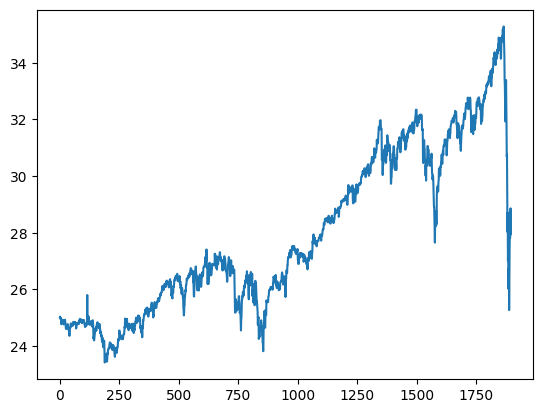

In [18]:
df['Close'].plot()
plt.show()

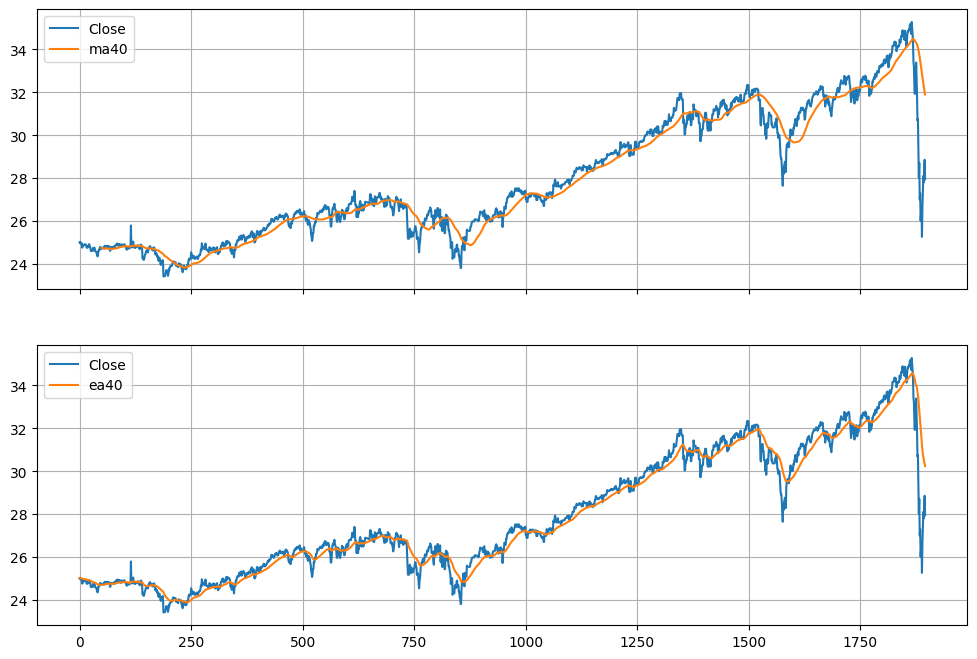

In [20]:
df['ma40']=df['Close'].rolling(50).mean() #window size is 50, average of those 50 prices (time)
df['ea40']=df['Close'].ewm(span=40,adjust=False).mean() #recursive - depends on time t-1
fig,axes=plt.subplots(2,1,sharex=True,figsize=(12,8))
df['Close'].plot(ax=axes[0],legend='Actual')
df['ma40'].plot(ax=axes[0],legend='Simple MA',grid=True)
df['Close'].plot(ax=axes[1],legend='Actual')
df['ea40'].plot(ax=axes[1],legend='Exponential MA',grid=True)
plt.legend()
plt.show()

In [22]:
#error MAE-y
mae_simple=(df['Close']-df['ma40']).abs().mean()
mae_exp=(df['Close']-df['ea40']).abs().mean()

print(f'Simple MA MAE:{mae_simple}')
print(f'Exponential MA MAE:{mae_exp}')

Simple MA MAE:0.44619672080279027
Exponential MA MAE:0.34399475847473737


Normalization

In [28]:
numeric_df = df.select_dtypes(include='number')

df_scaled = (numeric_df - numeric_df.min()) / (numeric_df.max() - numeric_df.min())
data=df_scaled.to_numpy()

SEQ_LENGTH = 150

X,y=[],[]

for i in range(len(data)-SEQ_LENGTH):
    X.append(data[i:i+SEQ_LENGTH])
    y.append(data[i+SEQ_LENGTH,3]) #3 signifies the 4th coloumn for the closing price

X,y=np.array(X),np.array(y)

In [30]:
split=int(0.8*len(X))
X_train,X_valid=X[:split],X[split:]
y_train,y_valid=y[:split],y[split:]
#tensorflow data conversion
BATCH_SIZE=32

train_dataset=tf.data.Dataset.from_tensor_slices((X_train,y_train)).batch(BATCH_SIZE).shuffle(buffer_size=1000)
valid_dataset=tf.data.Dataset.from_tensor_slices((X_valid,y_valid)).batch(BATCH_SIZE)

In [44]:
model=tf.keras.models.Sequential([
    tf.keras.layers.SimpleRNN(32,return_sequences=True,recurrent_dropout=0.2,input_shape=[None,8]),
    tf.keras.layers.SimpleRNN(64,return_sequences=False),
    tf.keras.layers.Dense(1)
])
model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn_12 (SimpleRNN)            │ (None, None, 32)            │           1,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn_13 (SimpleRNN)            │ (None, 64)                  │           6,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,585 (29.63 KB)

 Trainable params: 7,585 (29.63 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
optimizer = tf.keras.optimizers.Nadam(learning_rate=0.001)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.Huber(),
    metrics=['mae']
)

model.fit(
    train_dataset,
    validation_data=valid_dataset,
    epochs=10
)

predictions = model.predict(valid_dataset)



Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 9/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: nan - mae: nan - val_loss: nan - val_mae: nan
Epoch 10/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - l

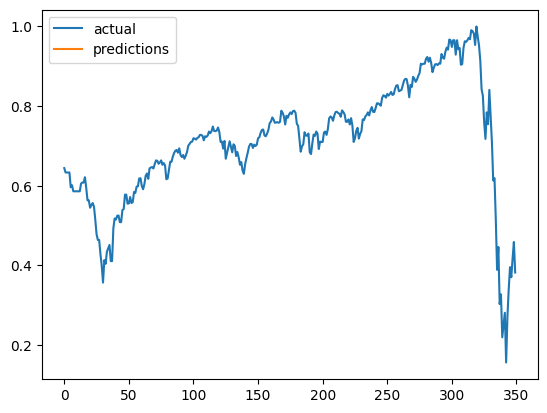

In [51]:
val_predictions=model.predict(valid_dataset,verbose=0)

plt.plot(y_valid,label='actual')

plt.plot(val_predictions,label='predictions')
plt.legend()
plt.show()

In [ ]:
#why am i not getting any predictions?
#date - 29/12/2025